# Function 8 — Week 10 full-cohort exploration

The 25 November snapshot contains 49 official observations and 29 published peer returns. 3 were added since 23 November.

[Model comparison](model_predictions.ipynb) · [Week 10 review](../../../../results/week-10-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 8
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
EXPECTED_ROUND_COUNTS = {0: 40, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-25"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 23 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 49
Published peer returns                29
New peer returns since 23 November     3
Total observations                    78
dtype: int64

## Measured scores

The close-up shows the five highest scores. The latest marker follows the official record. Peer round labels are local to each reporting repository.

Round 8 return                       9.874267
Rank among official observations     3.000000
Rank in the full snapshot           11.000000
Best official score                  9.936773
Best published peer score            9.946588
dtype: float64

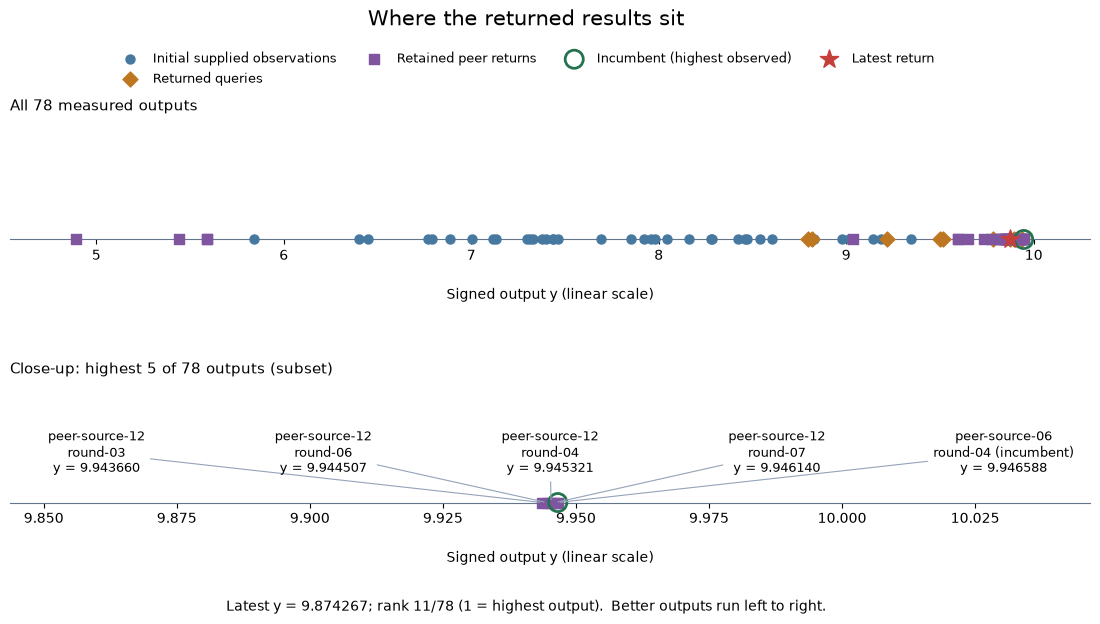

In [4]:
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_output_review, plot_round_progress, plot_input_profiles,
)

prepared = prepare_weekly_observation_review(review, history=official_data)
latest = prepared["latest"]
latest_official_rank = int((official_data.y > latest.y).sum()) + 1
latest_cohort_rank = int((review["data"].y > latest.y).sum()) + 1
display(pd.Series({"Round 8 return": latest.y, "Rank among official observations": latest_official_rank,
    "Rank in the full snapshot": latest_cohort_rank, "Best official score": official_data.y.max(),
    "Best published peer score": peer_data.y.max()}))
display(plot_output_review(review, save_to=FIGURES / "observed-output-review.png"))


## Official progress

The running maximum follows the eight official returns.

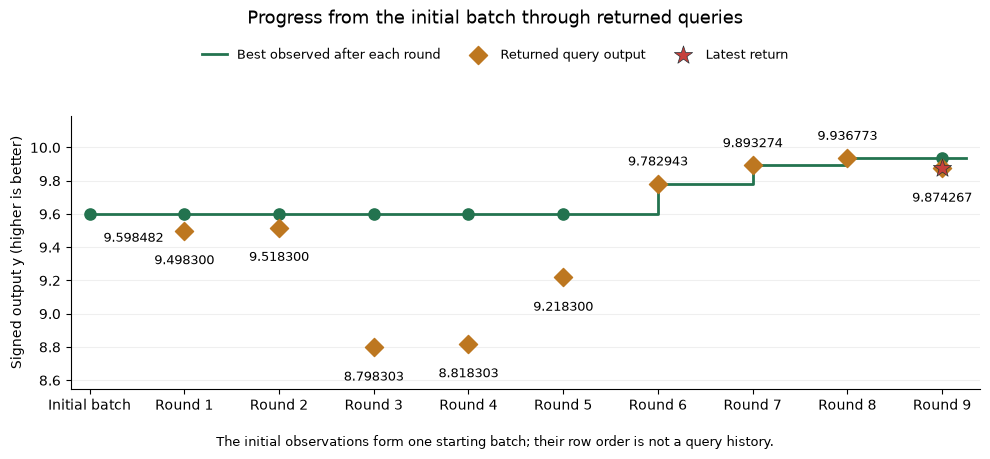

,returned_y,best_y,change_vs_prior_best
stage,,,
Initial batch,NaN,9.598482,NaN
Round 1,9.498300,9.598482,-0.100182
Round 2,9.518300,9.598482,-0.080182
Round 3,8.798303,9.598482,-0.800179
Round 4,8.818303,9.598482,-0.780179
Round 5,9.218300,9.598482,-0.380182
Round 6,9.782943,9.782943,0.184461
Round 7,9.893274,9.893274,0.110331
Round 8,9.936773,9.936773,0.043500


In [5]:
display(plot_round_progress(prepared["progress"], save_to=FIGURES / "official-progress.png"))
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]])


## Strongest measured input profiles

Colour encodes input settings on a common 0–1 scale.

,rank,observation_id,x1,x2,x3,x4,x5,x6,x7,x8,y
63,1,peer-source-06-round-04,0.1160,0.0650,0.1140,0.0220,0.912000,0.6490,0.2010,0.6220,9.946588
75,2,peer-source-12-round-07,0.1399,0.0761,0.1679,0.0099,0.999999,0.5040,0.2178,0.5209,9.946140
67,3,peer-source-12-round-04,0.1260,0.0800,0.1660,0.0000,0.999999,0.5030,0.2280,0.5320,9.945321
74,4,peer-source-12-round-06,0.1387,0.0564,0.1707,0.0000,0.968400,0.4995,0.2236,0.5013,9.944507
66,5,peer-source-12-round-03,0.1250,0.0600,0.1600,0.0000,0.999999,0.4900,0.2000,0.4700,9.943660


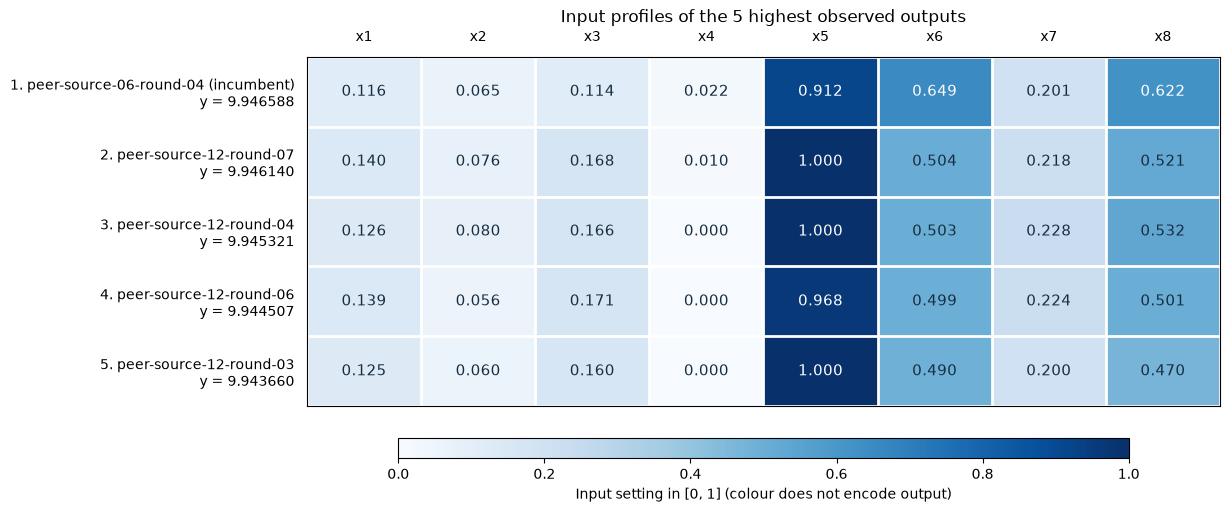

In [6]:
display(prepared["strongest"][["rank", "observation_id", *INPUT_COLUMNS, "y"]])
display(plot_input_profiles(prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=latest.observation_id, incumbent_id=prepared["incumbent"].observation_id,
    save_to=FIGURES / "strongest-input-profiles.png"))


In [7]:
summary = dict(function=FUNCTION_NUMBER, intake_date="2026-11-25",
    official_rows=intake["official"], peer_rows=intake["peer"], new_peer_rows=intake["new_peer"],
    latest_output=float(latest.y), latest_official_rank=latest_official_rank,
    latest_cohort_rank=latest_cohort_rank, official_best=float(official_data.y.max()),
    peer_best=float(peer_data.y.max()), best_peer_point=intake["peer_best_point"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "observation-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 8,
  "intake_date": "2026-11-25",
  "official_rows": 49,
  "peer_rows": 29,
  "new_peer_rows": 3,
  "latest_output": 9.8742673678714,
  "latest_official_rank": 3,
  "latest_cohort_rank": 11,
  "official_best": 9.9367734246634,
  "peer_best": 9.9465876,
  "best_peer_point": [
    0.116,
    0.065,
    0.114,
    0.022,
    0.912,
    0.649,
    0.201,
    0.622
  ],
  "official_snapshot_sha256": "dddb7e960da7bd55c069be8fb83110ebd22784e4c41f4d5ca90c6583951a75b9",
  "pooled_snapshot_sha256": "cc2ee10b362184620c65e3ceffc79d7b5b890d0ffdaf7ed848b9f6cd56f6c075"
}


## Preprocessing and validation diagnostics

Compare the middle half of each coordinate distribution and the empirical score distributions for official and published peer observations. Repeated groups use the rounded portal input across all coordinates. A peer at the same portal point as an official hold-out is withheld during validation. The model study tests median aggregation of training repeats and a higher assumed peer noise level. [Modelling experiments](model_predictions.ipynb#extended-cohort-surrogate-study)

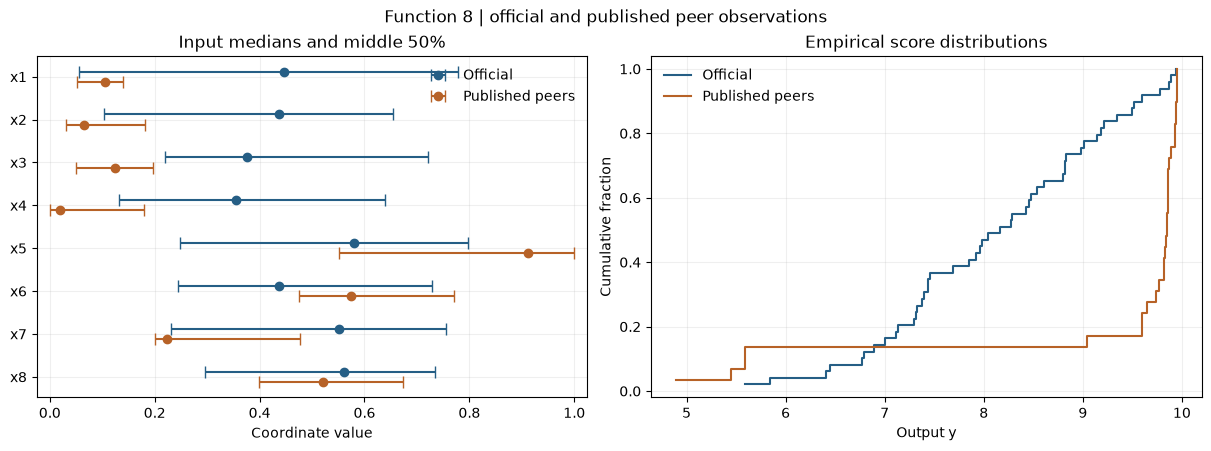

,scope,rows,rows_on_portal_boundary,score_median
0,Official,49,8,8.159983
1,Published peers,29,13,9.845450


portal_input_groups                 77.0000
repeated_input_groups                1.0000
peer_rows_matching_official          1.0000
median_peer_to_official_distance     0.2902
dtype: float64

In [8]:
from cohort_surrogate_plots import cohort_data_diagnostics

official_scores = official_data.y.to_numpy(dtype=float)
peer_scores = peer_data.y.to_numpy(dtype=float)
label = "Output y"
if FUNCTION_NUMBER == 1:
    function_helpers = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(function_helpers) not in sys.path:
        sys.path.insert(0, str(function_helpers))
    from function_1_model_helpers import signed_log
    official_scores = signed_log(official_scores, scale=1e-200)
    peer_scores = signed_log(peer_scores, scale=1e-200)
    label = "Signed-log height h"
diagnostics, distribution = cohort_data_diagnostics(review, official_scores, peer_scores,
    title=f"Function {FUNCTION_NUMBER} | official and published peer observations",
    target_label=label, save_to=FIGURES / "cohort-data-diagnostics.png")
display(distribution)
display(pd.DataFrame(diagnostics["by_scope"]))
display(pd.Series({key: value for key, value in diagnostics.items() if key != "by_scope"}))


### Interpreting the diagnostics

The score and input summaries compare different collections of queried points. Peer round numbers are local to their sources. The official timeline above uses the confirmed email returns.